# Plataforma Big Data para Data Science - Explorar las bases del proyecto: Presupuesto de la cena (JupyterLab)

**Autores:** 
1. Joel Víctor Peña Carhuapoma
2. Sonia Curasma Quispe

Este notebook hace **todo el recorrido** con las bases del proyecto: ubicar los datos → identificar formatos → ver el contenido → abrir cada base → consultar → revisar la calidad → graficar → crear una tabla nueva → ejecutar las consultas C1–C7 del informe (Anexo D).

**Antes de empezar**
1. Se trabajo con los archivos `foodcom` y `wearable` (de Canvas) dentro de la carpeta `datos/` del proyecto, como indica `datos/README.md`.
2. En la carpeta del proyecto, se preparo el entorno y se abrió JupyterLab: `uv sync` y luego `uv run jupyter lab`.
3. Abre este notebook (`entregas/E1/anexos/explorar_bases.ipynb`).


## Etapa 1. Revisar la máquina y las herramientas
Se fija la carpeta de trabajo (proyecto), que contiene `datos/`, se muestra cuánto disco libre hay y la versión de Python.

In [48]:
import sys, os, shutil, platform
BASE = next((os.path.abspath(r) for r in ['.', '..', '../..', '../../..'] if os.path.isdir(os.path.join(r, 'datos'))), None)
if BASE is None:
    raise FileNotFoundError('No encuentro la carpeta datos/. Abre JupyterLab desde la carpeta del proyecto '
                            '(la que contiene datos/) y descomprime ahí las bases, como indica datos/README.md.')
os.chdir(BASE)
print('Carpeta del proyecto:', BASE)
total, usado, libre = shutil.disk_usage(BASE)
print(f'Disco libre: {libre/1e9:.0f} GB de {total/1e9:.0f} GB')
print('Python', sys.version.split()[0], '|', platform.system())

Carpeta del proyecto: C:\MAESTRIA_CHILE_UC\PLATAFORMA BIG DATA\Proyecto\inf3862-proyecto
Disco libre: 599 GB de 959 GB
Python 3.13.7 | Windows


In [49]:
# Librerías: las instala `uv sync` (ver pyproject.toml)
import duckdb
import pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 250)   # mostrar tablas anchas completas
print('DuckDB', duckdb.__version__, '| pandas', pd.__version__)

DuckDB 2.0.0 | pandas 3.1.1


## Etapa 2. Ubicar los datos
Las bases se ubican en la carpeta **`datos/`** del proyecto. Esta celda muestra qué hay en ella y cuánto pesa cada elemento.

In [50]:
DATOS = os.path.join(BASE, 'datos')
for f in sorted(os.listdir(DATOS)):
    p = os.path.join(DATOS, f)
    print(f'{f:28s} {os.path.getsize(p)/1e6:9.1f} MB' if os.path.isfile(p) else f'{f:28s}   (carpeta)')

LEEME.md                           0.0 MB
README.md                          0.0 MB
foodcom                        (carpeta)
wearable                       (carpeta)


## Etapa 3. Identificar el formato de cada archivo

| Firma (primeros bytes) | Formato |
|---|---|
| `PK` | ZIP |
| `Rar!` | RAR |
| `1f 8b` | gzip (`.gz`) |
| `PAR1` | Parquet |
| `{` | JSON |
| texto con comas | CSV |


In [51]:
def que_formato(ruta):
    with open(ruta, 'rb') as f:          # 'rb' = leer como bytes, sin interpretar
        ini = f.read(4)
    if ini[:2] == b'PK':      return 'ZIP (comprimido, varias carpetas)'
    if ini[:4] == b'Rar!':    return 'RAR (comprimido, varias carpetas)'
    if ini[:2] == b'\x1f\x8b': return 'gzip (un archivo comprimido)'
    if ini[:4] == b'PAR1':    return 'Parquet (tabla binaria por columnas)'
    if ini[:1] in (b'{', b'['): return 'JSON / JSON Lines (texto con etiquetas)'
    if ini[:1] == b'#':       return 'Markdown (texto con formato)'
    return 'Texto (probablemente CSV)'

def listar_archivos(carpeta):
    """Archivos de la carpeta y sus subcarpetas (sin entrar en 'mediciones', que tiene 1.449)."""
    for raiz, carpetas, archivos in os.walk(carpeta):
        carpetas[:] = sorted(c for c in carpetas if not c.startswith('.') and c != 'mediciones')
        for f in sorted(archivos):
            yield os.path.join(raiz, f)

for p in listar_archivos(DATOS):
    print(f'{os.path.relpath(p, DATOS):32s} -> {que_formato(p)}')

LEEME.md                         -> Markdown (texto con formato)
README.md                        -> Markdown (texto con formato)
foodcom\recipes.parquet          -> Parquet (tabla binaria por columnas)
foodcom\reviews.parquet          -> Parquet (tabla binaria por columnas)
wearable\LEEME.md                -> Markdown (texto con formato)
wearable\comidas.csv             -> Texto (probablemente CSV)
wearable\dispositivos.csv        -> Texto (probablemente CSV)
wearable\sesiones.jsonl          -> JSON / JSON Lines (texto con etiquetas)


In [52]:
# La «firma» vista directamente: los primeros 8 bytes de cada archivo
for p in listar_archivos(DATOS):
    with open(p, 'rb') as f:
        print(f'{os.path.relpath(p, DATOS):32s}', f.read(8))

LEEME.md                         b'# Datos '
README.md                        b'# Datos '
foodcom\recipes.parquet          b'PAR1\x15\x04\x15\x80'
foodcom\reviews.parquet          b'PAR1\x15\x04\x15\x80'
wearable\LEEME.md                b'# Datos '
wearable\comidas.csv             b'comida_i'
wearable\dispositivos.csv        b'device_i'
wearable\sesiones.jsonl          b'{"sessio'


## Etapa 4. Verificar la estructura
Las bases quedan así:
```
datos/foodcom/recipes.parquet, reviews.parquet
datos/wearable/dispositivos.csv, comidas.csv, sesiones.jsonl, LEEME.md, mediciones/AAAA-MM-DD/HH.jsonl.gz
```
Los **`.gz` de las mediciones no se descomprimen**: DuckDB los lee directamente, y descomprimidos ocuparían 2,2 GB.

In [53]:
import glob
esperado = ['foodcom/recipes.parquet', 'foodcom/reviews.parquet', 'wearable/dispositivos.csv',
            'wearable/comidas.csv', 'wearable/sesiones.jsonl', 'wearable/LEEME.md']
faltan = [e for e in esperado if not os.path.exists(os.path.join(DATOS, e))]
for e in esperado:
    print('OK  ' if e not in faltan else 'FALTA', e)
n = len(glob.glob(f'{DATOS}/wearable/mediciones/*/*.jsonl.gz'))
print('OK  ' if n == 1449 else 'REVISAR', f'mediciones: {n} archivos (se esperan 1.449)')
if faltan or n == 0:
    raise FileNotFoundError('Faltan datos: descomprime foodcom.rar y wearable.rar dentro de datos/ (ver datos/README.md).')

OK   foodcom/recipes.parquet
OK   foodcom/reviews.parquet
OK   wearable/dispositivos.csv
OK   wearable/comidas.csv
OK   wearable/sesiones.jsonl
OK   wearable/LEEME.md
OK   mediciones: 1449 archivos (se esperan 1.449)


## Etapa 5. Ver qué hay dentro, sin abrir nada todavía
### 5.1. El árbol de carpetas, con tamaños

In [54]:
filas = []
for raiz, carpetas, archivos in os.walk(DATOS):
    carpetas[:] = [c for c in carpetas if not c.startswith('.')]   # ignora carpetas ocultas
    for a in archivos:
        p = os.path.join(raiz, a)
        grupo = 'wearable/mediciones/*/*.jsonl.gz' if '/mediciones/' in p else os.path.relpath(p, DATOS)
        filas.append((grupo, os.path.getsize(p)))
t = pd.DataFrame(filas, columns=['archivo', 'bytes']).groupby('archivo').agg(n_archivos=('bytes', 'size'), MB=('bytes', 'sum'))
t['MB'] = (t['MB'] / 1e6).round(1)
t

,n_archivos,MB
archivo,,
LEEME.md,1,0.0
README.md,1,0.0
foodcom\recipes.parquet,1,178.7
foodcom\reviews.parquet,1,173.8
wearable\LEEME.md,1,0.0
...,...,...
wearable\mediciones\2008-02-14\10.jsonl.gz,1,0.0
wearable\mediciones\2008-02-14\11.jsonl.gz,1,0.0
wearable\mediciones\2008-02-14\12.jsonl.gz,1,0.0


In [55]:
# Las carpetas de mediciones: una por día de RECEPCIÓN y un archivo por hora
dias = sorted(os.listdir(f'{DATOS}/wearable/mediciones'))
print(len(dias), 'días, del', dias[0], 'al', dias[-1])
print('Archivos del primer día:', sorted(os.listdir(f'{DATOS}/wearable/mediciones/{dias[0]}'))[:6], '...')

61 días, del 2007-12-16 al 2008-02-14
Archivos del primer día: ['05.jsonl.gz', '06.jsonl.gz', '07.jsonl.gz', '08.jsonl.gz', '09.jsonl.gz', '10.jsonl.gz'] ...


### 5.2. Leer el LEEME (el manual de los datos)

In [56]:
from IPython.display import Markdown, display
display(Markdown(open(f'{DATOS}/wearable/LEEME.md', encoding='utf-8').read()))

# Datos del wearable · Proyecto INF3862

Datos sintéticos de relojes inteligentes vinculados a usuarios reales de Food.com
(`AuthorId`) y a recetas reales (`RecipeId`). Todas las fechas están en UTC; usen
`zona_horaria` de `dispositivos.csv` para pasar a hora local.

## Archivos

### `dispositivos.csv`
Un reloj vinculado a un usuario. Un usuario puede tener más de un reloj si lo cambió.

| Campo | Descripción |
|---|---|
| `device_id` | Identificador del reloj |
| `AuthorId` | Usuario de Food.com |
| `modelo` | `Pulso S` o `FitBand 2` |
| `fecha_vinculacion` | Cuándo se vinculó a la app |
| `fecha_desvinculacion` | Vacío si sigue activo |
| `zona_horaria` | Zona horaria del usuario |

### `mediciones/AAAA-MM-DD/HH.jsonl.gz`
Mediciones recibidas por la app, agrupadas por **día y hora de recepción** (no de
medición). Cada reloj las envía en lotes cuando se sincroniza con el teléfono.
Los dos modelos usan formatos distintos:

| Pulso S | FitBand 2 | Descripción |
|---|---|---|
| `device_id` | `dev` | Reloj |
| `ts_medicion` (ISO 8601) | `timestamp` (epoch en milisegundos) | Momento de la medición |
| `ts_recepcion` | `received_at` | Momento en que llegó a la app |
| `frecuencia_cardiaca` | `fc` | Latidos por minuto (puede venir nulo) |
| `pasos` | `steps` | Pasos desde la medición anterior |
| `calorias` | `kcal` | Calorías desde la medición anterior |

Pulso S mide cada minuto y FitBand 2 cada cinco. Durante una sesión de actividad
ambos miden cada 10 segundos.

### `sesiones.jsonl`
Una actividad registrada: `session_id`, `device_id`, `tipo` (caminar, correr,
bicicleta, fuerza), `inicio`, `fin`, `distancia_km` (nulo en fuerza) y `calorias`.

### `comidas.csv`
Una receta preparada por un usuario, registrada desde la app: `comida_id`,
`AuthorId`, `RecipeId`, `fecha_hora` y `porciones`.

## Advertencia

Como en un sistema real, estos datos no vienen limpios. Revisen duplicados,
datos faltantes, registros que llegan tarde, referencias que no calzan y
diferencias entre modelos antes de analizarlos.


### 5.3. Mirar los archivos de texto «en crudo»
- La función `primeras_lineas` muestra las primeras líneas de un archivo de texto.
- Si el archivo es `.gz`, lo descomprime «al vuelo» con `gzip.open`, sin guardar el resultado.

In [57]:
import gzip
def primeras_lineas(ruta, n):
    abrir = gzip.open if ruta.endswith('.gz') else open
    with abrir(ruta, 'rt', encoding='utf-8') as f:
        for _ in range(n):
            print(f.readline().rstrip())

print('=== dispositivos.csv (CSV: valores separados por comas) ===')
primeras_lineas(f'{DATOS}/wearable/dispositivos.csv', 3)
print('\n=== comidas.csv ===')
primeras_lineas(f'{DATOS}/wearable/comidas.csv', 3)
print('\n=== sesiones.jsonl (JSON Lines: una ficha por línea) ===')
primeras_lineas(f'{DATOS}/wearable/sesiones.jsonl', 2)
print('\n=== una medición (dentro de un .jsonl.gz) ===')
primeras_lineas(f'{DATOS}/wearable/mediciones/2007-12-17/20.jsonl.gz', 2)

=== dispositivos.csv (CSV: valores separados por comas) ===
device_id,AuthorId,modelo,fecha_vinculacion,fecha_desvinculacion,zona_horaria
W00001,337859,Pulso S,2007-11-07T16:18:51Z,,America/Denver
W00002,541842,FitBand 2,2007-12-05T11:51:33Z,,America/Chicago

=== comidas.csv ===
comida_id,AuthorId,RecipeId,fecha_hora,porciones
C0000001,64203,105893,2007-12-16T00:02:25Z,1
C0000002,414923,128503,2007-12-16T00:05:03Z,2

=== sesiones.jsonl (JSON Lines: una ficha por línea) ===
{"session_id":"S000001","device_id":"W00290","tipo":"caminar","inicio":"2007-12-16T11:10:33Z","fin":"2007-12-16T12:16:33Z","distancia_km":6.15,"calorias":300.6}
{"session_id":"S000002","device_id":"W00241","tipo":"bicicleta","inicio":"2007-12-16T11:41:21Z","fin":"2007-12-16T12:09:21Z","distancia_km":7.75,"calorias":267.6}

=== una medición (dentro de un .jsonl.gz) ===
{"device_id":"W00214","ts_medicion":"2007-12-17T18:50:00Z","ts_recepcion":"2007-12-17T20:00:23Z","frecuencia_cardiaca":85,"pasos":2,"calorias":1.0}
{"d

### 5.4. Leer una línea JSON con Python
`json.loads` convierte el texto en un **diccionario**: pares «etiqueta → valor». Así se ve que el FitBand 2 usa nombres distintos.

In [58]:
import gzip, json
with gzip.open(f'{DATOS}/wearable/mediciones/2007-12-17/20.jsonl.gz', 'rt') as f:
    lineas = f.read().splitlines()
pulso = json.loads(next(l for l in lineas if '"device_id"' in l))
fitband = json.loads(next(l for l in lineas if '"dev"' in l))
print('Pulso S  :', pulso)
print('FitBand 2:', fitband)
print('Etiqueta "pasos" del Pulso S =', pulso['pasos'], '| etiqueta "steps" del FitBand 2 =', fitband['steps'])

Pulso S  : {'device_id': 'W00214', 'ts_medicion': '2007-12-17T18:50:00Z', 'ts_recepcion': '2007-12-17T20:00:23Z', 'frecuencia_cardiaca': 85, 'pasos': 2, 'calorias': 1.0}
FitBand 2: {'dev': 'W00078', 'timestamp': 1197881400000, 'received_at': '2007-12-17T20:05:20Z', 'fc': 65, 'steps': 0, 'kcal': 5.17}
Etiqueta "pasos" del Pulso S = 2 | etiqueta "steps" del FitBand 2 = 0


### 5.5. Mirar «por dentro» un Parquet sin cargarlo

In [59]:
for nombre in ['recipes', 'reviews']:
    ruta = f'{DATOS}/foodcom/{nombre}.parquet'
    meta = duckdb.sql(f"SELECT num_rows, num_row_groups FROM parquet_file_metadata('{ruta}')").fetchall()[0]
    print(f'{nombre}.parquet: {meta[0]:,} filas guardadas en {meta[1]} bloques')
# Esquema (columnas y tipos) de reviews.parquet, leído del encabezado del archivo
duckdb.sql(f"SELECT name AS columna, type AS tipo_fisico, converted_type AS tipo_logico FROM parquet_schema('{DATOS}/foodcom/reviews.parquet') WHERE name <> 'schema'").df()

recipes.parquet: 522,517 filas guardadas en 1 bloques
reviews.parquet: 1,401,982 filas guardadas en 1 bloques


,columna,tipo_fisico,tipo_logico
0,ReviewId,INT32,NaN
1,RecipeId,INT32,NaN
2,AuthorId,INT32,NaN
3,AuthorName,BYTE_ARRAY,UTF8
4,Rating,INT32,NaN
5,Review,BYTE_ARRAY,UTF8
6,DateSubmitted,INT64,TIMESTAMP_MICROS
7,DateModified,INT64,TIMESTAMP_MICROS


## Etapa 6. Abrir cada base como tabla (DuckDB + SQL)

In [60]:
con = duckdb.connect()                  # base de datos en memoria
con.sql("SET TimeZone = 'UTC'")         # muestra las fechas en UTC
D = DATOS
con.sql(f"CREATE OR REPLACE VIEW recetas      AS SELECT * FROM '{D}/foodcom/recipes.parquet'")
con.sql(f"CREATE OR REPLACE VIEW resenas      AS SELECT * FROM '{D}/foodcom/reviews.parquet'")
con.sql(f"CREATE OR REPLACE VIEW dispositivos AS SELECT * FROM read_csv('{D}/wearable/dispositivos.csv')")
con.sql(f"CREATE OR REPLACE VIEW comidas      AS SELECT * FROM read_csv('{D}/wearable/comidas.csv')")
con.sql(f"CREATE OR REPLACE VIEW sesiones     AS SELECT * FROM read_json('{D}/wearable/sesiones.jsonl')")
con.sql("SHOW TABLES").df()

,name
0,comidas
1,dispositivos
2,recetas
3,resenas
4,sesiones


### 6.1. ¿Cuántas filas tiene cada base?

In [61]:
con.sql("""
SELECT 'recetas' AS base, count(*) AS filas FROM recetas UNION ALL
SELECT 'resenas',      count(*) FROM resenas      UNION ALL
SELECT 'dispositivos', count(*) FROM dispositivos UNION ALL
SELECT 'comidas',      count(*) FROM comidas      UNION ALL
SELECT 'sesiones',     count(*) FROM sesiones
""").df()

,base,filas
0,recetas,522517
1,resenas,1401982
2,dispositivos,315
3,comidas,22106
4,sesiones,4840


### 6.2. Columnas y tipos de cada base
`DESCRIBE` es el «diccionario de variables» de una tabla. Tipos frecuentes:
- `VARCHAR`: texto;
- `BIGINT` o `INTEGER`: número entero;
- `DOUBLE`: número con decimales;
- `TIMESTAMP WITH TIME ZONE`: fecha y hora;
- `VARCHAR[]`: **lista** de textos.

In [62]:
con.sql("DESCRIBE recetas").df()[['column_name', 'column_type']]

,column_name,column_type
0,RecipeId,DOUBLE
1,Name,VARCHAR
2,AuthorId,INTEGER
3,AuthorName,VARCHAR
4,CookTime,VARCHAR
5,PrepTime,VARCHAR
6,TotalTime,VARCHAR
7,DatePublished,TIMESTAMP WITH TIME ZONE
8,Description,VARCHAR
9,Images,VARCHAR[]


In [63]:
for tabla in ['resenas', 'dispositivos', 'comidas', 'sesiones']:
    print(f'--- {tabla} ---')
    print(con.sql(f"DESCRIBE {tabla}").df()[['column_name', 'column_type']].to_string(index=False), '\n')

--- resenas ---
  column_name              column_type
     ReviewId                  INTEGER
     RecipeId                  INTEGER
     AuthorId                  INTEGER
   AuthorName                  VARCHAR
       Rating                  INTEGER
       Review                  VARCHAR
DateSubmitted TIMESTAMP WITH TIME ZONE
 DateModified TIMESTAMP WITH TIME ZONE 

--- dispositivos ---
         column_name              column_type
           device_id                  VARCHAR
            AuthorId                   BIGINT
              modelo                  VARCHAR
   fecha_vinculacion TIMESTAMP WITH TIME ZONE
fecha_desvinculacion TIMESTAMP WITH TIME ZONE
        zona_horaria                  VARCHAR 

--- comidas ---
column_name              column_type
  comida_id                  VARCHAR
   AuthorId                   BIGINT
   RecipeId                   BIGINT
 fecha_hora TIMESTAMP WITH TIME ZONE
  porciones                   BIGINT 

--- sesiones ---
 column_name              col

### 6.3. Ver algunas filas de cada base
`SELECT columnas FROM tabla LIMIT 5` muestra 5 filas.

In [64]:
con.sql("SELECT RecipeId, Name, RecipeCategory, Calories, ProteinContent, RecipeServings, TotalTime, AggregatedRating FROM recetas LIMIT 5").df()

,RecipeId,Name,RecipeCategory,Calories,ProteinContent,RecipeServings,TotalTime,AggregatedRating
0,38.0,Low-Fat Berry Blue Frozen Dessert,Frozen Desserts,170.9,3.2,4,PT24H45M,4.5
1,39.0,Biryani,Chicken Breast,1110.7,63.4,6,PT4H25M,3.0
2,40.0,Best Lemonade,Beverages,311.1,0.3,4,PT35M,4.5
3,41.0,Carina's Tofu-Vegetable Kebabs,Soy/Tofu,536.1,29.3,2,PT24H20M,4.5
4,42.0,Cabbage Soup,Vegetable,103.6,4.3,4,PT50M,4.5


In [65]:
con.sql("SELECT ReviewId, RecipeId, AuthorId, Rating, left(Review, 60) AS inicio_texto, DateSubmitted FROM resenas LIMIT 5").df()

,ReviewId,RecipeId,AuthorId,Rating,inicio_texto,DateSubmitted
0,2,992,2008,5,better than any you can get at a restaurant!,2000-01-25 21:44:00+00:00
1,7,4384,1634,4,"I cut back on the mayo, and made up the differ...",2001-10-17 16:49:59+00:00
2,9,4523,2046,2,i think i did something wrong because i could ...,2000-02-25 09:00:00+00:00
3,13,7435,1773,5,easily the best i have ever had. juicy flavor...,2000-03-13 21:15:00+00:00
4,14,44,2085,5,An excellent dish.,2000-03-28 12:51:00+00:00


In [66]:
con.sql("SELECT * FROM dispositivos LIMIT 5").df()

,device_id,AuthorId,modelo,fecha_vinculacion,fecha_desvinculacion,zona_horaria
0,W00001,337859,Pulso S,2007-11-07 16:18:51+00:00,NaT,America/Denver
1,W00002,541842,FitBand 2,2007-12-05 11:51:33+00:00,NaT,America/Chicago
2,W00003,102058,FitBand 2,2007-11-04 16:13:40+00:00,NaT,America/Chicago
3,W00004,312577,FitBand 2,2008-01-01 09:47:10+00:00,NaT,America/New_York
4,W00005,68526,Pulso S,2008-01-13 16:00:36+00:00,NaT,America/Chicago


In [67]:
con.sql("SELECT * FROM comidas LIMIT 5").df()

,comida_id,AuthorId,RecipeId,fecha_hora,porciones
0,C0000001,64203,105893,2007-12-16 00:02:25+00:00,1
1,C0000002,414923,128503,2007-12-16 00:05:03+00:00,2
2,C0000003,369715,271300,2007-12-16 00:07:52+00:00,4
3,C0000004,465056,239398,2007-12-16 00:15:51+00:00,2
4,C0000005,66246,23744,2007-12-16 00:20:02+00:00,2


In [68]:
con.sql("SELECT * FROM sesiones LIMIT 5").df()

,session_id,device_id,tipo,inicio,fin,distancia_km,calorias
0,S000001,W00290,caminar,2007-12-16 11:10:33+00:00,2007-12-16 12:16:33+00:00,6.15,300.6
1,S000002,W00241,bicicleta,2007-12-16 11:41:21+00:00,2007-12-16 12:09:21+00:00,7.75,267.6
2,S000003,W00150,correr,2007-12-16 12:07:07+00:00,2007-12-16 12:59:07+00:00,8.80,581.6
3,S000004,W00313,correr,2007-12-16 12:10:51+00:00,2007-12-16 12:51:51+00:00,6.91,504.2
4,S000005,W00010,fuerza,2007-12-16 12:18:27+00:00,2007-12-16 13:08:27+00:00,NaN,297.4


### 6.4. Las mediciones: 1.449 archivos y dos formatos → una sola tabla
- `read_json('…/mediciones/*/*.jsonl.gz')` lee **todos** los archivos. El `*` significa «cualquier nombre».
- `columns={…}` declara las 12 etiquetas posibles (6 del Pulso S y 6 del FitBand 2) y su tipo.
- `coalesce(a, b)` toma `a`, y si está vacío toma `b`: así se **unifican los nombres**.
- `to_timestamp(timestamp/1000)` convierte milisegundos desde 1970 en fecha.
- `CREATE TABLE` (no `VIEW`) **guarda el resultado en memoria**, para que las consultas siguientes sean rápidas.

In [69]:
con.sql("SET preserve_insertion_order = false")   # ahorra memoria
con.sql(f"""
CREATE OR REPLACE TABLE mediciones AS
SELECT coalesce(device_id, dev)                            AS device_id,
       coalesce(ts_medicion, to_timestamp(timestamp/1000)) AS ts_medicion,
       coalesce(ts_recepcion, received_at)                 AS ts_recepcion,
       coalesce(frecuencia_cardiaca, fc)                   AS frecuencia_cardiaca,
       coalesce(pasos, steps)                              AS pasos,
       coalesce(calorias, kcal)                            AS calorias,
       CASE WHEN dev IS NULL THEN 'Pulso S' ELSE 'FitBand 2' END AS formato
FROM read_json('{D}/wearable/mediciones/*/*.jsonl.gz', format='newline_delimited',
     columns={{device_id:'VARCHAR', ts_medicion:'TIMESTAMPTZ', ts_recepcion:'TIMESTAMPTZ',
              frecuencia_cardiaca:'INTEGER', pasos:'INTEGER', calorias:'DOUBLE',
              dev:'VARCHAR', timestamp:'BIGINT', received_at:'TIMESTAMPTZ',
              fc:'INTEGER', steps:'INTEGER', kcal:'DOUBLE'}})
""")
con.sql("SELECT formato, count(*) AS mediciones, count(DISTINCT device_id) AS relojes, min(ts_medicion) AS desde, max(ts_medicion) AS hasta FROM mediciones GROUP BY formato").df()

,formato,mediciones,relojes,desde,hasta
0,Pulso S,13515447,198,2007-12-16 05:00:00+00:00,2008-02-14 07:59:00+00:00
1,FitBand 2,2024685,117,2007-12-16 05:00:00+00:00,2008-02-14 07:55:00+00:00


In [71]:
con.sql("SELECT * FROM mediciones WHERE device_id = 'W00177' ORDER BY ts_medicion LIMIT 5").df()

,device_id,ts_medicion,ts_recepcion,frecuencia_cardiaca,pasos,calorias,formato
0,W00177,2007-12-16 06:00:00+00:00,2007-12-16 06:33:01+00:00,52,0,1.13,Pulso S
1,W00177,2007-12-16 06:01:00+00:00,2007-12-16 06:33:01+00:00,49,0,1.13,Pulso S
2,W00177,2007-12-16 06:02:00+00:00,2007-12-16 06:33:01+00:00,49,0,1.13,Pulso S
3,W00177,2007-12-16 06:03:00+00:00,2007-12-16 06:33:01+00:00,50,0,1.13,Pulso S
4,W00177,2007-12-16 06:04:00+00:00,2007-12-16 06:33:01+00:00,55,0,1.13,Pulso S


## Etapa 7. Consultas para explorar (SQL paso a paso)

**7.1. Filtrar filas con `WHERE`**: Recetas de la categoría *Chicken* con menos de 300 kcal por porción.

In [72]:
con.sql("""
SELECT Name, Calories, ProteinContent, AggregatedRating, ReviewCount
FROM recetas
WHERE RecipeCategory = 'Chicken' AND Calories < 300 AND ReviewCount >= 50
ORDER BY AggregatedRating DESC, ReviewCount DESC
LIMIT 10
""").df()

,Name,Calories,ProteinContent,AggregatedRating,ReviewCount
0,Salsa Chicken,267.5,33.1,5.0,217
1,Charlie's Famous Chicken Salad With Grapes,206.6,18.2,5.0,217
2,Artichoke and Chicken Bake,268.6,35.2,5.0,195
3,Baked Balsamic Chicken,170.3,15.3,5.0,170
4,Italian Chopped Salad in Shells,64.7,3.3,5.0,169
5,Baked Pesto Chicken,197.5,30.2,5.0,156
6,Pronto Pups aka Corn Dogs,214.0,6.7,5.0,134
7,Stir-Fry Chicken With Garlic Sauce,277.5,26.3,5.0,125
8,"Shredded Chicken for Enchiladas, Tostadas, Tac...",111.4,12.4,5.0,125
9,Balsamic Chicken,209.3,25.7,5.0,121


**7.2. Agrupar y resumir con `GROUP BY`**: las 10 categorías con más recetas, con sus calorías promedio (`avg`) y su mediana.

In [73]:
con.sql("""
SELECT RecipeCategory, count(*) AS recetas, round(avg(Calories)) AS kcal_promedio, round(median(Calories)) AS kcal_mediana
FROM recetas GROUP BY RecipeCategory ORDER BY recetas DESC LIMIT 10
""").df()

,RecipeCategory,recetas,kcal_promedio,kcal_mediana
0,Dessert,62072,644.0,327.0
1,Lunch/Snacks,32586,438.0,330.0
2,One Dish Meal,31345,530.0,455.0
3,Vegetable,27231,272.0,195.0
4,Breakfast,21101,383.0,304.0
5,Beverages,16076,283.0,139.0
6,Chicken,13249,537.0,437.0
7,Meat,13131,606.0,434.0
8,Breads,12804,619.0,275.0
9,Pork,12603,558.0,434.0


**7.3. Unir tablas con `JOIN`**: a cada comida se le traen el nombre y las calorías de su receta, y se calculan las kcal consumidas = kcal por porción × porciones.

In [74]:
con.sql("""
SELECT c.comida_id, c.AuthorId, c.fecha_hora, c.porciones, r.Name, r.Calories AS kcal_porcion,
       round(r.Calories * c.porciones, 1) AS kcal_consumidas
FROM comidas c
LEFT JOIN recetas r ON r.RecipeId = c.RecipeId
ORDER BY c.comida_id
LIMIT 5
""").df()

,comida_id,AuthorId,fecha_hora,porciones,Name,kcal_porcion,kcal_consumidas
0,C0000001,64203,2007-12-16 00:02:25+00:00,1,Black Bean and Chicken Quesadillas,384.4,384.4
1,C0000002,414923,2007-12-16 00:05:03+00:00,2,My Dad Swears My Sister Makes the Best Pork Ch...,745.8,1491.6
2,C0000003,369715,2007-12-16 00:07:52+00:00,4,Green Beans and Mushroom,52.9,211.6
3,C0000004,465056,2007-12-16 00:15:51+00:00,2,Family Favorite Sesame Chicken,428.2,856.4
4,C0000005,66246,2007-12-16 00:20:02+00:00,2,Linguine With Garlic Shrimp,370.0,740.0


**7.4. Pasar de UTC a hora local** con `AT TIME ZONE` y la zona de cada persona (columna `zona_horaria` de dispositivos). ¿A qué hora local se registran las comidas?

In [75]:
horas = con.sql("""
WITH zona AS (SELECT DISTINCT AuthorId, zona_horaria FROM dispositivos)
SELECT hour(c.fecha_hora AT TIME ZONE z.zona_horaria) AS hora_local, count(*) AS comidas
FROM comidas c JOIN zona z USING (AuthorId)
GROUP BY hora_local ORDER BY hora_local
""").df()
horas.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
hora_local,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
comidas,92,106,100,84,86,96,118,3424,3403,97,92,105,3389,3344,126,113,109,118,119,3383,3280,102,108,112


**7.5. Combinar varias bases:** calorías gastadas (reloj) y consumidas (comidas) de una persona en un día. `WITH` crea tablas temporales con nombre, para escribir la consulta por partes.

In [76]:
con.sql("""
WITH g AS (SELECT sum(calorias) AS kcal
           FROM (SELECT DISTINCT device_id, ts_medicion, calorias FROM mediciones WHERE device_id = 'W00177')
           WHERE (ts_medicion AT TIME ZONE 'America/Chicago')::DATE = DATE '2007-12-17'),
     c AS (SELECT sum(r.Calories * c.porciones) AS kcal FROM comidas c JOIN recetas r USING (RecipeId)
           WHERE c.AuthorId = 238476 AND (c.fecha_hora AT TIME ZONE 'America/Chicago')::DATE = DATE '2007-12-17')
SELECT round(g.kcal, 1) AS kcal_gastadas, round(c.kcal, 1) AS kcal_consumidas, round(c.kcal - g.kcal, 1) AS balance
FROM g, c
""").df()

,kcal_gastadas,kcal_consumidas,balance
0,2537.0,1868.4,-668.6


**7.6. Pasar un resultado a pandas y seguir trabajando en Python.** `.df()` entrega una tabla de pandas (`DataFrame`), sobre la que se pueden hacer cálculos, filtros o gráficos.

In [77]:
disp = con.sql("SELECT * FROM dispositivos").df()
print(type(disp))
print(disp['modelo'].value_counts())                       # frecuencia de cada modelo
print('Zonas horarias:', disp['zona_horaria'].unique())

<class 'pandas.DataFrame'>
modelo
Pulso S      198
FitBand 2    117
Name: count, dtype: int64
Zonas horarias: <ArrowStringArray>
['America/Denver', 'America/Chicago', 'America/New_York', 'America/Los_Angeles']
Length: 4, dtype: str


## Etapa 8. Revisar la calidad de los datos
Son los problemas que el LEEME y el enunciado piden detectar, contados sobre todos los datos.

In [78]:
con.sql("""
WITH rep AS (SELECT device_id, ts_medicion, count(*) AS veces FROM mediciones GROUP BY ALL HAVING count(*) > 1)
SELECT 'Mediciones repetidas (copias de más)' AS problema, sum(veces - 1)::BIGINT AS registros FROM rep
UNION ALL SELECT 'Mediciones sin frecuencia cardíaca', count(*) FILTER (WHERE frecuencia_cardiaca IS NULL) FROM mediciones
UNION ALL SELECT 'Mediciones que llegan con más de 24 h de atraso', count(*) FILTER (WHERE ts_recepcion - ts_medicion > INTERVAL 24 HOUR) FROM mediciones
UNION ALL SELECT 'Comidas con receta inexistente', count(*) FROM comidas c ANTI JOIN recetas r ON r.RecipeId = c.RecipeId
UNION ALL SELECT 'Sesiones duplicadas (mismo reloj e inicio)', count(*) - count(DISTINCT (device_id, inicio)) FROM sesiones
UNION ALL SELECT 'Recetas sin porciones', count(*) FILTER (WHERE RecipeServings IS NULL) FROM recetas
UNION ALL SELECT 'Recetas con más de 3.000 kcal por porción', count(*) FILTER (WHERE Calories > 3000) FROM recetas
UNION ALL SELECT 'Reseñas con nota 0', count(*) FILTER (WHERE Rating = 0) FROM resenas
""").df()

,problema,registros
0,Mediciones sin frecuencia cardíaca,357927
1,Mediciones repetidas (copias de más),345599
2,Mediciones que llegan con más de 24 h de atraso,400614
3,Comidas con receta inexistente,48
4,Sesiones duplicadas (mismo reloj e inicio),48
5,Recetas sin porciones,182911
6,Recetas con más de 3.000 kcal por porción,7622
7,Reseñas con nota 0,76248


In [79]:
# ¿Cuánto tardan en llegar las mediciones? (horas). quantile_cont = percentil
con.sql("""
SELECT round(quantile_cont(h, 0.5), 1) AS mediana_h, round(quantile_cont(h, 0.9), 1) AS p90_h,
       round(quantile_cont(h, 0.99), 1) AS p99_h, round(max(h), 1) AS maximo_h
FROM (SELECT epoch(ts_recepcion - ts_medicion) / 3600 AS h FROM mediciones)
""").df()

,mediana_h,p90_h,p99_h,maximo_h
0,1.3,7.9,33.9,107.7


## Etapa 9. Visualizar
`matplotlib` es la librería de gráficos de Python (la instala `uv sync`). Cada gráfico sigue tres pasos: preparar la tabla con SQL → dibujar → poner títulos.

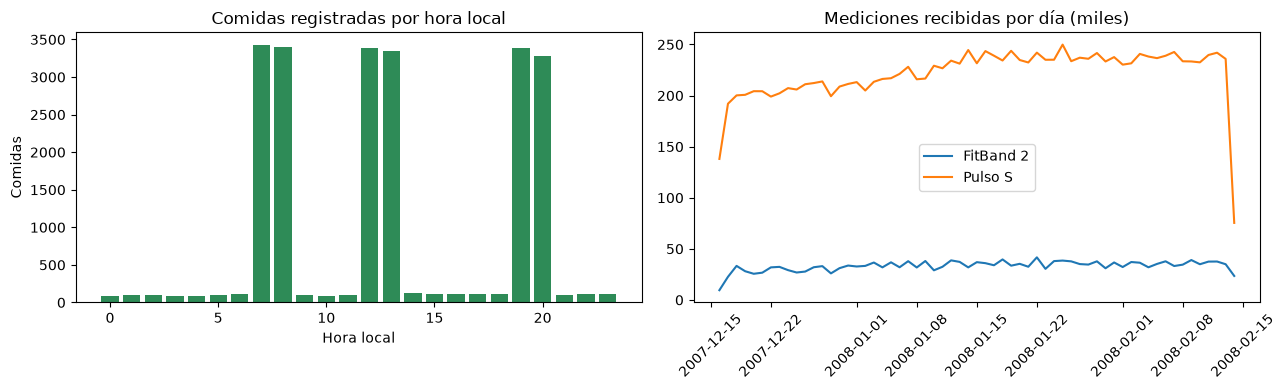

In [80]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
# (a) Comidas por hora local (tabla 'horas' de la etapa 7.4)
ax[0].bar(horas['hora_local'], horas['comidas'], color='#2E8B57')
ax[0].set_title('Comidas registradas por hora local'); ax[0].set_xlabel('Hora local'); ax[0].set_ylabel('Comidas')
# (b) Mediciones recibidas por día, según el modelo de reloj
por_dia = con.sql("""SELECT ts_recepcion::DATE AS dia, formato, count(*) AS n FROM mediciones GROUP BY ALL ORDER BY dia""").df()
for modelo, g in por_dia.groupby('formato'):
    ax[1].plot(g['dia'], g['n'] / 1e3, label=modelo)
ax[1].set_title('Mediciones recibidas por día (miles)'); ax[1].legend(); ax[1].tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

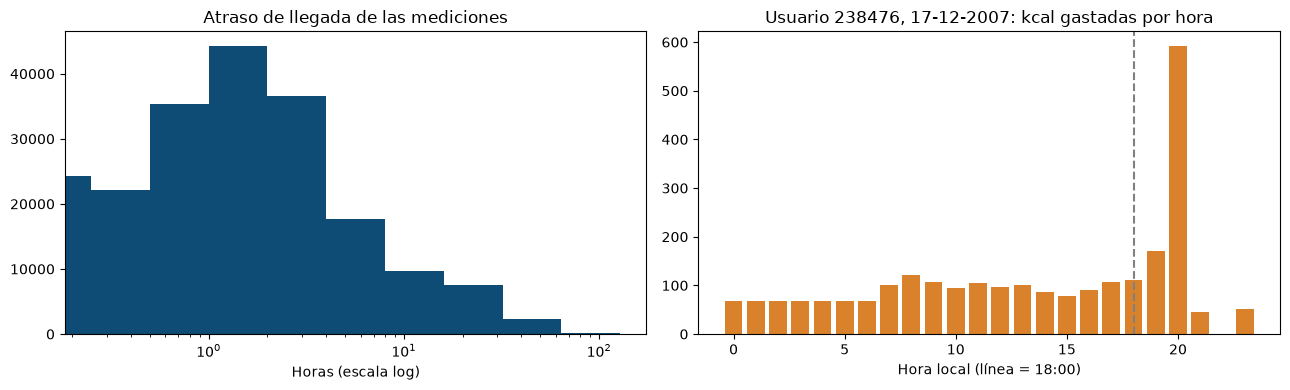

In [81]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
# (c) Atraso de llegada (horas, escala logarítmica)
atraso = con.sql("SELECT epoch(ts_recepcion - ts_medicion)/3600 AS h FROM mediciones USING SAMPLE 200000").df()
ax[0].hist(atraso['h'], bins=[0, .25, .5, 1, 2, 4, 8, 16, 32, 64, 128], color='#0F4C75')
ax[0].set_xscale('log'); ax[0].set_title('Atraso de llegada de las mediciones'); ax[0].set_xlabel('Horas (escala log)')
# (d) Un día de una persona: calorías gastadas por hora local
dia = con.sql("""
WITH m AS (SELECT DISTINCT ts_medicion, calorias FROM mediciones WHERE device_id = 'W00177')
SELECT hour(ts_medicion AT TIME ZONE 'America/Chicago') AS hora, sum(calorias) AS kcal
FROM m WHERE (ts_medicion AT TIME ZONE 'America/Chicago')::DATE = DATE '2007-12-17' GROUP BY hora ORDER BY hora""").df()
ax[1].bar(dia['hora'], dia['kcal'], color='#D9822B'); ax[1].axvline(18, ls='--', color='gray')
ax[1].set_title('Usuario 238476, 17-12-2007: kcal gastadas por hora'); ax[1].set_xlabel('Hora local (línea = 18:00)')
plt.tight_layout(); plt.show()

## Etapa 10. Manipular: crear una tabla nueva
Se construye la tabla **usuario-día** (el «panel» del proyecto): una fila por persona y día local, con pasos, kcal gastadas, kcal gastadas hasta las 18:00 y kcal consumidas. Pasos:
1. Eliminar las mediciones repetidas (`DISTINCT`);
2. Asignar cada reloj a su persona y zona horaria, según el periodo en que estuvo vinculado;
3. Sumar por persona, día local y reloj;
4. Si alguien tuvo dos relojes vinculados el mismo día (6 personas), quedarse con el de más mediciones, para no contar dos veces el gasto;
5. Unir con las comidas, acotando a 3.000 kcal por porción las recetas con valores absurdos.

In [82]:
con.sql("""
CREATE OR REPLACE TABLE usuario_dia AS
WITH m AS (SELECT DISTINCT device_id, ts_medicion, pasos, calorias FROM mediciones),
     m_persona AS (
        SELECT d.AuthorId, d.device_id, d.modelo, (m.ts_medicion AT TIME ZONE d.zona_horaria) AS local, m.pasos, m.calorias
        FROM m JOIN dispositivos d
          ON d.device_id = m.device_id
         AND m.ts_medicion >= d.fecha_vinculacion
         AND (d.fecha_desvinculacion IS NULL OR m.ts_medicion < d.fecha_desvinculacion)),
     por_reloj AS (
        SELECT AuthorId, local::DATE AS fecha_local, device_id, modelo, count(*) AS n_mediciones,
               sum(pasos) AS pasos, round(sum(calorias), 1) AS kcal_gastadas,
               round(sum(calorias) FILTER (WHERE hour(local) < 18), 1) AS kcal_gastadas_18h
        FROM m_persona GROUP BY ALL),
     gasto AS (          -- si una persona tuvo 2 relojes ese día, se queda con el de más mediciones
        SELECT * EXCLUDE (n_mediciones) FROM por_reloj
        QUALIFY row_number() OVER (PARTITION BY AuthorId, fecha_local ORDER BY n_mediciones DESC) = 1),
     zona AS (SELECT DISTINCT AuthorId, zona_horaria FROM dispositivos),
     consumo AS (
        SELECT c.AuthorId, (c.fecha_hora AT TIME ZONE z.zona_horaria)::DATE AS fecha_local,
               count(*) AS comidas, round(sum(least(r.Calories, 3000) * c.porciones), 1) AS kcal_consumidas   -- acota recetas absurdas (> 3.000 kcal/porción)
        FROM comidas c JOIN recetas r ON r.RecipeId = c.RecipeId JOIN zona z ON z.AuthorId = c.AuthorId GROUP BY ALL)
SELECT g.*, coalesce(c.comidas, 0) AS comidas, c.kcal_consumidas,
       round(c.kcal_consumidas - g.kcal_gastadas, 1) AS balance
FROM gasto g LEFT JOIN consumo c USING (AuthorId, fecha_local)
""")
con.sql("SELECT count(*) AS filas, count(DISTINCT AuthorId) AS personas, min(fecha_local) AS desde, max(fecha_local) AS hasta FROM usuario_dia").df()

,filas,personas,desde,hasta
0,16330,300,2007-12-16,2008-02-13


In [83]:
con.sql("SELECT * FROM usuario_dia WHERE AuthorId = 238476 ORDER BY fecha_local LIMIT 5").df()

,AuthorId,fecha_local,device_id,modelo,pasos,kcal_gastadas,kcal_gastadas_18h,comidas,kcal_consumidas,balance
0,238476,2007-12-16,W00177,Pulso S,14578.0,2016.2,1479.3,2,3932.4,1916.2
1,238476,2007-12-17,W00177,Pulso S,21954.0,2536.9,1566.0,2,1868.4,-668.5
2,238476,2007-12-18,W00177,Pulso S,6023.0,1793.5,1408.1,0,NaN,NaN
3,238476,2007-12-19,W00177,Pulso S,5731.0,1745.7,1410.0,1,648.8,-1096.9
4,238476,2007-12-20,W00177,Pulso S,4473.0,1734.9,1359.8,0,NaN,NaN


## Etapa 11. Las consultas del informe (C1–C7) sobre los datos reales

Aquí se construye una **versión mínima** de esas tablas a partir de los archivos y se ejecutan las 7 consultas, adaptadas lo justo. Sirve para tres cosas:
1. Comprobar que el diseño funciona;
2. Ver los resultados con datos reales;
3. Adelantar la E2, que pide «ejecutar las tres consultas analíticas de la E1».

Como el periodo de datos es 2007–2008, «hoy» será el último día con datos: **14-02-2008**.

### 11.1. Crear las tablas operacionales (OLTP) del informe
Se crean con sus **reglas**: clave primaria (`PRIMARY KEY`), clave foránea (`REFERENCES`) y restricciones (`CHECK`). Luego se llenan con los datos. Las 48 comidas cuya receta no existe **no pueden entrar** (la clave foránea lo impide), así que se filtran y se cuentan.

In [84]:
con.sql("""
CREATE OR REPLACE TABLE usuario (usuario_id BIGINT PRIMARY KEY);
CREATE OR REPLACE TABLE dispositivo (device_id VARCHAR PRIMARY KEY, modelo VARCHAR, zona_horaria VARCHAR);
CREATE OR REPLACE TABLE receta (receta_id BIGINT PRIMARY KEY, nombre VARCHAR, categoria VARCHAR,
                                kcal_porcion DOUBLE, nota DOUBLE, n_resenas INTEGER);
CREATE OR REPLACE SEQUENCE seq_vinc START 1;
CREATE OR REPLACE TABLE vinculacion (vinculacion_id BIGINT PRIMARY KEY DEFAULT nextval('seq_vinc'),
       device_id VARCHAR REFERENCES dispositivo (device_id), usuario_id BIGINT REFERENCES usuario (usuario_id),
       inicio TIMESTAMPTZ, fin TIMESTAMPTZ);
CREATE OR REPLACE SEQUENCE seq_comida START 1;
CREATE OR REPLACE TABLE comida (comida_id BIGINT PRIMARY KEY DEFAULT nextval('seq_comida'),
       usuario_id BIGINT REFERENCES usuario (usuario_id), receta_id BIGINT REFERENCES receta (receta_id),
       fecha_hora TIMESTAMPTZ, porciones INTEGER CHECK (porciones > 0));
""")
con.sql("INSERT INTO usuario SELECT DISTINCT AuthorId FROM dispositivos")
con.sql("INSERT INTO dispositivo SELECT device_id, modelo, zona_horaria FROM dispositivos")
con.sql("INSERT INTO vinculacion (device_id, usuario_id, inicio, fin) SELECT device_id, AuthorId, fecha_vinculacion, fecha_desvinculacion FROM dispositivos ORDER BY fecha_vinculacion")
con.sql("INSERT INTO receta SELECT RecipeId::BIGINT, Name, RecipeCategory, Calories, AggregatedRating, ReviewCount FROM recetas")
con.sql("""INSERT INTO comida (usuario_id, receta_id, fecha_hora, porciones)
           SELECT AuthorId, RecipeId, fecha_hora, porciones FROM comidas
           WHERE RecipeId IN (SELECT receta_id FROM receta) ORDER BY fecha_hora""")
con.sql("""SELECT 'usuario' AS tabla, count(*) AS filas FROM usuario UNION ALL SELECT 'dispositivo', count(*) FROM dispositivo
   UNION ALL SELECT 'vinculacion', count(*) FROM vinculacion UNION ALL SELECT 'receta', count(*) FROM receta
   UNION ALL SELECT 'comida', count(*) FROM comida
   UNION ALL SELECT 'comidas excluidas (receta inexistente)', (SELECT count(*) FROM comidas) - (SELECT count(*) FROM comida)""").df()

,tabla,filas
0,receta,522517
1,vinculacion,315
2,usuario,300
3,comida,22058
4,dispositivo,315
5,comidas excluidas (receta inexistente),48


### C1. Vincular un reloj (OLTP con transacción)
El reloj `W00001` pasa a otra persona. Hay que **cerrar** la vinculación vigente y **abrir** la nueva en una sola transacción:
- `BEGIN TRANSACTION` empieza el bloque;
- `COMMIT` confirma los dos cambios juntos;
- Si algo falla, `ROLLBACK` deshace todo.

In [85]:
nuevo_duenio = con.sql("SELECT min(usuario_id) FROM usuario WHERE usuario_id <> (SELECT usuario_id FROM vinculacion WHERE device_id = 'W00001' AND fin IS NULL)").fetchall()[0][0]
print('ANTES');  print(con.sql("SELECT * FROM vinculacion WHERE device_id = 'W00001' ORDER BY inicio").df())
con.execute("BEGIN TRANSACTION")
con.execute("UPDATE vinculacion SET fin = TIMESTAMPTZ '2008-02-14 12:00:00+00' WHERE device_id = 'W00001' AND fin IS NULL")
con.execute("INSERT INTO vinculacion (device_id, usuario_id, inicio) VALUES ('W00001', ?, TIMESTAMPTZ '2008-02-14 12:00:00+00')", [nuevo_duenio])
con.execute("COMMIT")
print('\nDESPUÉS'); print(con.sql("SELECT * FROM vinculacion WHERE device_id = 'W00001' ORDER BY inicio").df())

ANTES
   vinculacion_id device_id  usuario_id                    inicio fin
0              89    W00001      337859 2007-11-07 16:18:51+00:00 NaT

DESPUÉS
   vinculacion_id device_id  usuario_id                    inicio                       fin
0              89    W00001      337859 2007-11-07 16:18:51+00:00 2008-02-14 12:00:00+00:00
1             316    W00001       11297 2008-02-14 12:00:00+00:00                       NaT


**¿Y si algo falla a la mitad?** Se intenta lo mismo con el reloj `W00002`, pero el nuevo dueño **no existe** (usuario 999). La inserción falla por la clave foránea y `ROLLBACK` deshace también el cierre ya hecho: el reloj **no queda sin dueño**.

In [86]:
antes = con.sql("SELECT * FROM vinculacion WHERE device_id = 'W00002'").df()
try:
    con.execute("BEGIN TRANSACTION")
    con.execute("UPDATE vinculacion SET fin = TIMESTAMPTZ '2008-02-14 12:00:00+00' WHERE device_id = 'W00002' AND fin IS NULL")
    con.execute("INSERT INTO vinculacion (device_id, usuario_id, inicio) VALUES ('W00002', 999, TIMESTAMPTZ '2008-02-14 12:00:00+00')")
    con.execute("COMMIT")
except Exception as e:
    con.execute("ROLLBACK")
    print('Falló:', str(e).splitlines()[0][:110], '→ ROLLBACK')
despues = con.sql("SELECT * FROM vinculacion WHERE device_id = 'W00002'").df()
print('¿La vinculación quedó intacta?', antes.equals(despues))
despues

Falló: Constraint Error: Violates foreign key constraint because key "usuario_id: 999" does not exist in the referenc → ROLLBACK
¿La vinculación quedó intacta? True


,vinculacion_id,device_id,usuario_id,inicio,fin
0,195,W00002,541842,2007-12-05 11:51:33+00:00,NaT


### C2. Registrar una comida (OLTP)
Se registra una comida válida. Después se intentan dos registros inválidos, que **las reglas rechazan**: una receta inexistente (clave foránea) y 0 porciones (`CHECK`).

In [87]:
con.execute("INSERT INTO comida (usuario_id, receta_id, fecha_hora, porciones) VALUES (238476, 38, TIMESTAMPTZ '2008-02-14 23:30:00+00', 2)")
print(con.sql("SELECT * FROM comida ORDER BY comida_id DESC LIMIT 1").df())
for receta, porciones, caso in [(999999999, 1, 'receta inexistente'), (38, 0, '0 porciones')]:
    try:
        con.execute("INSERT INTO comida (usuario_id, receta_id, fecha_hora, porciones) VALUES (238476, ?, TIMESTAMPTZ '2008-02-14 23:40:00+00', ?)", [receta, porciones])
    except Exception as e:
        print(f'Rechazada ({caso}):', str(e).splitlines()[0][:100])

   comida_id  usuario_id  receta_id                fecha_hora  porciones
0      22059      238476         38 2008-02-14 23:30:00+00:00          2
Rechazada (receta inexistente): Constraint Error: Violates foreign key constraint because key "receta_id: 999999999" does not exist 
Rechazada (0 porciones): Constraint Error: CHECK constraint failed on table "comida" with expression CHECK((porciones > 0))


### C3. Ver las comidas de hoy (OLTP)
Las comidas de la persona 238476 en su día local 17-12-2007. En Chicago (UTC−6), ese día va de las 06:00 UTC del 17 a las 06:00 UTC del 18.

In [88]:
con.sql("""
SELECT c.fecha_hora, r.nombre, c.porciones, round(c.porciones * r.kcal_porcion, 1) AS kcal
FROM comida c JOIN receta r ON r.receta_id = c.receta_id
WHERE c.usuario_id = 238476
  AND c.fecha_hora >= TIMESTAMPTZ '2007-12-17 06:00:00+00' AND c.fecha_hora < TIMESTAMPTZ '2007-12-18 06:00:00+00'
ORDER BY c.fecha_hora
""").df()

,fecha_hora,nombre,porciones,kcal
0,2007-12-17 14:12:06+00:00,White Trash Chocolate Pie,3,1321.2
1,2007-12-18 01:36:07+00:00,Asparagus With Beer and Honey Sauce,4,547.2


### 11.2. Crear las tablas analíticas (OLAP) del informe
Se construyen a partir de la tabla `usuario_dia` de la etapa 10:
- `dim_usuario` y `dim_fecha`, cada una con su clave (`usuario_key`, `fecha_key`);
- `fct_balance_diario`, que agrega `pct_cobertura`: la fracción de minutos del día con alguna medición, que mide la calidad del dato. El Pulso S mide 1.440 veces al día y el FitBand 2, 288.

In [89]:
con.sql("""
CREATE OR REPLACE TABLE dim_usuario AS
SELECT row_number() OVER (ORDER BY AuthorId) AS usuario_key, AuthorId AS usuario_id,
       any_value(modelo) AS modelo_reloj, any_value(zona_horaria) AS zona_horaria
FROM dispositivos GROUP BY AuthorId;
CREATE OR REPLACE TABLE dim_fecha AS
SELECT row_number() OVER (ORDER BY fecha) AS fecha_key, fecha, dayname(fecha) AS dia_semana,
       isodow(fecha) >= 6 AS fin_de_semana, month(fecha) AS mes, year(fecha) AS anio
FROM (SELECT DISTINCT fecha_local AS fecha FROM usuario_dia);
CREATE OR REPLACE TABLE fct_balance_diario AS
WITH cob AS (
  SELECT m.device_id, (m.ts_medicion AT TIME ZONE d.zona_horaria)::DATE AS fecha_local,
         count(DISTINCT date_trunc('minute', m.ts_medicion)) AS minutos
  FROM mediciones m JOIN dispositivos d USING (device_id) GROUP BY ALL)
SELECT u.usuario_key, f.fecha_key, b.pasos, b.kcal_gastadas, b.kcal_gastadas_18h AS kcal_gastadas_hasta_18h,
       b.kcal_consumidas, b.comidas AS n_comidas, b.balance AS balance_kcal,
       round(least(1.0, cob.minutos / CASE WHEN b.modelo = 'Pulso S' THEN 1440 ELSE 288 END), 3) AS pct_cobertura
FROM usuario_dia b
JOIN dim_usuario u ON u.usuario_id = b.AuthorId
JOIN dim_fecha f ON f.fecha = b.fecha_local
LEFT JOIN cob ON cob.device_id = b.device_id AND cob.fecha_local = b.fecha_local;
""")
con.sql("SELECT count(*) AS filas, round(avg(pct_cobertura), 3) AS cobertura_prom, count(*) FILTER (WHERE pct_cobertura >= 0.8) AS dias_cobertura_80 FROM fct_balance_diario").df()

,filas,cobertura_prom,dias_cobertura_80
0,16330,0.854,11869


### C4. Balance diario y media de 7 días (OLAP - responde el objetivo)
Es la consulta del informe, sin cambios. Solo cambia `:hoy`, que pasa a ser el 14-02-2008. `AVG(...) OVER (... ROWS BETWEEN 6 PRECEDING AND CURRENT ROW)` es una **media móvil**: el promedio de los últimos 7 días de cada persona.

In [90]:
c4 = con.sql("""
SELECT u.usuario_id, f.fecha, b.kcal_gastadas, b.kcal_consumidas, b.balance_kcal,
       round(AVG(b.balance_kcal) OVER (PARTITION BY u.usuario_id ORDER BY f.fecha
                                       ROWS BETWEEN 6 PRECEDING AND CURRENT ROW), 1) AS balance_media_7d
FROM fct_balance_diario b
JOIN dim_usuario u ON u.usuario_key = b.usuario_key
JOIN dim_fecha   f ON f.fecha_key   = b.fecha_key
WHERE f.fecha BETWEEN DATE '2008-02-14' - 30 AND DATE '2008-02-14' - 1
  AND b.pct_cobertura >= 0.8
ORDER BY u.usuario_id, f.fecha
""").df()
print(len(c4), 'filas (persona-día) en los últimos 30 días')
c4[c4.usuario_id == 238476].tail(7)

6215 filas (persona-día) en los últimos 30 días


,usuario_id,fecha,kcal_gastadas,kcal_consumidas,balance_kcal,balance_media_7d
1853,238476,2008-02-06,1715.6,817.4,-898.2,-329.8
1854,238476,2008-02-07,1996.2,748.3,-1247.9,-316.9
1855,238476,2008-02-08,1666.8,200.9,-1465.9,-575.9
1856,238476,2008-02-09,1721.6,NaN,NaN,-887.4
1857,238476,2008-02-10,1682.5,0.0,-1682.5,-1008.6
1858,238476,2008-02-11,1947.8,904.7,-1043.1,-1062.3
1859,238476,2008-02-12,1722.1,7110.5,5388.4,-158.2


### C5. Fracción del gasto ocurrida antes de las 18:00 (OLAP)
Es la consulta del informe. El resultado es la «regla simple» que usa C7 y la referencia que el modelo de la E3 tendrá que superar.

In [91]:
c5 = con.sql("""
SELECT u.modelo_reloj, f.fin_de_semana,
       round(AVG(b.kcal_gastadas_hasta_18h / NULLIF(b.kcal_gastadas, 0)), 3) AS fraccion_18h,
       COUNT(*) AS dias
FROM fct_balance_diario b JOIN dim_usuario u USING (usuario_key)
                          JOIN dim_fecha   f USING (fecha_key)
WHERE f.fecha >= DATE '2008-02-14' - 90 AND b.pct_cobertura >= 0.8
GROUP BY u.modelo_reloj, f.fin_de_semana ORDER BY 1, 2
""").df()
c5

,modelo_reloj,fin_de_semana,fraccion_18h,dias
0,FitBand 2,False,0.792,3242
1,FitBand 2,True,0.790,1277
2,Pulso S,False,0.794,5275
3,Pulso S,True,0.796,2075


### C6. Recetas más preparadas en la cena después de cada actividad (OLAP)
Primero se construyen `dim_actividad` y `fct_comida`. La «actividad previa» de una comida es la última sesión de esa persona que **terminó antes** de la comida, el mismo día local; si no hubo ninguna, es «sin actividad». Luego se ejecuta la consulta del informe, que deja las 3 recetas más frecuentes por tipo con `QUALIFY`.

In [92]:
con.sql("""
CREATE OR REPLACE TABLE dim_actividad AS
SELECT row_number() OVER (ORDER BY tipo) AS actividad_key, tipo
FROM (SELECT DISTINCT tipo FROM sesiones UNION SELECT 'sin actividad');
CREATE OR REPLACE TABLE dim_receta AS
SELECT row_number() OVER (ORDER BY receta_id) AS receta_key, receta_id, nombre, categoria, kcal_porcion, nota AS calificacion_promedio
FROM receta;
CREATE OR REPLACE TABLE fct_comida AS
WITH c AS (
  SELECT c.comida_id, c.usuario_id, c.receta_id, c.porciones, c.fecha_hora, z.zona_horaria,
         (c.fecha_hora AT TIME ZONE z.zona_horaria) AS local
  FROM comida c JOIN (SELECT DISTINCT AuthorId, zona_horaria FROM dispositivos) z ON z.AuthorId = c.usuario_id),
ses AS (SELECT DISTINCT s.device_id, s.tipo, s.inicio, s.fin, d.AuthorId FROM sesiones s JOIN dispositivos d USING (device_id)),
previa AS (
  SELECT c.comida_id, max_by(ses.tipo, ses.fin) AS tipo
  FROM c JOIN ses ON ses.AuthorId = c.usuario_id AND ses.fin <= c.fecha_hora
                 AND (ses.fin AT TIME ZONE c.zona_horaria)::DATE = c.local::DATE
  GROUP BY c.comida_id)
SELECT c.comida_id, u.usuario_key, f.fecha_key, r.receta_key, a.actividad_key,
       hour(c.local) AS hora_local, c.porciones, round(c.porciones * least(r.kcal_porcion, 3000), 1) AS kcal
FROM c
JOIN dim_usuario u ON u.usuario_id = c.usuario_id
JOIN dim_fecha f ON f.fecha = c.local::DATE
JOIN dim_receta r ON r.receta_id = c.receta_id
JOIN dim_actividad a ON a.tipo = coalesce((SELECT tipo FROM previa p WHERE p.comida_id = c.comida_id), 'sin actividad');
""")
con.sql("""
SELECT a.tipo, r.categoria, r.receta_id, r.nombre,
       COUNT(*) AS veces, round(AVG(c.kcal)) AS kcal_prom, MAX(r.calificacion_promedio) AS nota
FROM fct_comida c JOIN dim_actividad a USING (actividad_key)
                  JOIN dim_receta    r USING (receta_key)
                  JOIN dim_fecha     f USING (fecha_key)
WHERE c.hora_local BETWEEN 18 AND 22 AND f.fecha >= DATE '2008-02-14' - 90
GROUP BY a.tipo, r.categoria, r.receta_id, r.nombre
QUALIFY row_number() OVER (PARTITION BY a.tipo ORDER BY COUNT(*) DESC, MAX(r.calificacion_promedio) DESC NULLS LAST) <= 3
ORDER BY a.tipo, veces DESC
""").df()

,tipo,categoria,receta_id,nombre,veces,kcal_prom,nota
0,bicicleta,Breads,17102,Indian Fry Bread,2,91.0,5.0
1,bicicleta,Chicken,128736,Asian Barbecue Chicken,2,1972.0,5.0
2,bicicleta,Savory Pies,198069,Italian Sausage and Pepper Pie,1,845.0,5.0
3,caminar,Vegetable,354402,Simple Cucumbers and Onions,2,392.0,5.0
4,caminar,Turkey Breasts,25518,Tender Crock Pot Turkey Breast,2,1754.0,5.0
5,caminar,Breakfast,319397,Different Cinnamon Sugar Toast,2,133.0,4.5
6,correr,Pork,101209,Pork Tenderloin Piquant,2,1166.0,5.0
7,correr,Lentil,132614,Kielbasa and Lentil Soup,2,2723.0,4.0
8,correr,Yeast Breads,234865,Swedish Cardamom Braid,1,9000.0,5.0
9,fuerza,Very Low Carbs,79606,Dirty Shrimp in Butter-Beer Sauce,2,282.0,5.0


### C7. Presupuesto de la cena al abrir la app (frontera)
Se simula lo que vería la persona 238476 al abrir la app a las **18:00 del 17-12-2007** (hora de Chicago, 00:00 UTC del 18):

**(a) El casillero clave-valor** suma solo las mediciones que **ya habían llegado** a esa hora (`ts_recepcion` ≤ 18:00), sin repetidas. Es un diccionario de Python que hace de «clave-valor».

**(b) La app** lee el casillero y estima el gasto total con la fracción de C5 (Pulso S, día de semana). Resta lo consumido y elige 5 recetas que caben, empezando por las candidatas de C6.

Al final se compara con el valor «oficial», recalculado cuando ya llegaron todos los lotes.

In [93]:
u, modelo, zona, dia = 238476, 'Pulso S', 'America/Chicago', '2007-12-17'
hora_app = '2007-12-18 00:00:00+00'      # 18:00 en Chicago
# (a) casillero clave-valor: lo que se sabía a las 18:00 (lotes ya recibidos)
casillero = {}
gasto_visto = con.sql(f"""
  SELECT sum(calorias) FROM (SELECT DISTINCT device_id, ts_medicion, calorias FROM mediciones
                             WHERE device_id = 'W00177' AND ts_recepcion <= TIMESTAMPTZ '{hora_app}'
                               AND (ts_medicion AT TIME ZONE '{zona}')::DATE = DATE '{dia}')""").fetchall()[0][0] or 0
consumido = con.sql(f"""
  SELECT coalesce(sum(c.porciones * r.kcal_porcion), 0) FROM comida c JOIN receta r USING (receta_id)
  WHERE c.usuario_id = {u} AND c.fecha_hora < TIMESTAMPTZ '{hora_app}'
    AND (c.fecha_hora AT TIME ZONE '{zona}')::DATE = DATE '{dia}'""").fetchall()[0][0]
casillero[f'{u}:{dia}'] = {'kcal_gastadas': round(gasto_visto, 1), 'kcal_consumidas': round(consumido, 1)}
print('Casillero clave-valor:', casillero)
# (b) la app: 1 lectura + cálculo
p = casillero[f'{u}:{dia}']
fraccion = c5[(c5.modelo_reloj == modelo) & (~c5.fin_de_semana)]['fraccion_18h'].iloc[0]
gasto_total = p['kcal_gastadas'] / fraccion
presupuesto = gasto_total + 0 - p['kcal_consumidas']          # meta de balance = 0
print(f'Fracción C5 = {fraccion} → gasto total estimado = {gasto_total:,.0f} kcal → presupuesto de la cena = {presupuesto:,.0f} kcal')
recetas = con.sql(f"""
  WITH cand AS (SELECT DISTINCT r.receta_id FROM fct_comida c JOIN dim_receta r USING (receta_key) WHERE c.hora_local BETWEEN 18 AND 22)
  SELECT nombre, categoria, round(kcal_porcion) AS kcal_porcion, nota, n_resenas,
         receta_id IN (SELECT receta_id FROM cand) AS candidata_c6
  FROM receta
  WHERE kcal_porcion BETWEEN {presupuesto} * 0.5 AND {presupuesto} AND nota >= 4.5 AND n_resenas >= 20
    AND categoria NOT IN ('Dessert', 'Beverages', 'Breads', 'Quick Breads', 'Bar Cookie', 'Drop Cookies', 'Cheesecake', 'Candy', 'Frozen Desserts', 'Pie', 'Breakfast')
  ORDER BY candidata_c6 DESC, nota DESC, n_resenas DESC LIMIT 5""").df()
recetas

Casillero clave-valor: {'238476:2007-12-17': {'kcal_gastadas': 1319.7, 'kcal_consumidas': 1321.2}}
Fracción C5 = 0.794 → gasto total estimado = 1,662 kcal → presupuesto de la cena = 341 kcal


,nombre,categoria,kcal_porcion,nota,n_resenas,candidata_c6
0,Scalloped Potatoes,Potato,288.0,5.0,848,True
1,Crock Pot Whole Chicken,Whole Chicken,327.0,5.0,767,True
2,My Family's Favorite Sloppy Joes (Pizza Joes),Lunch/Snacks,325.0,5.0,756,True
3,Mexican Rice,Long Grain Rice,280.0,5.0,644,True
4,Best Grape Salad,Cheese,299.0,5.0,475,True


In [94]:
# El valor de las 18:00 era PROVISORIO: ¿cuánto había gastado realmente hasta las 18:00 (con todos los lotes)?
oficial = con.sql(f"""
  SELECT sum(calorias) FROM (SELECT DISTINCT device_id, ts_medicion, calorias FROM mediciones WHERE device_id = 'W00177')
  WHERE (ts_medicion AT TIME ZONE '{zona}')::DATE = DATE '{dia}' AND hour(ts_medicion AT TIME ZONE '{zona}') < 18""").fetchall()[0][0]
print(f'A las 18:00 la app veía {gasto_visto:,.1f} kcal; con todos los lotes, el gasto hasta las 18:00 fue {oficial:,.1f} kcal.')
print('Diferencia por lotes que llegaron después de las 18:00:', round(oficial - gasto_visto, 1), 'kcal')

A las 18:00 la app veía 1,319.7 kcal; con todos los lotes, el gasto hasta las 18:00 fue 1,566.0 kcal.
Diferencia por lotes que llegaron después de las 18:00: 246.3 kcal
